---

# Baseline and Linear Models

*By Aryan.*

In this part we train a baseline, linear regression, ridge, lasso, and logistic regression.
We do both tasks, predicting `valence` (regression) and predicting whether a song is sad, meaning `valence < 0.3` (classification).
The inputs are the 141 features in `train_features.csv`. All tuning is done with 5-fold cross-validation on the training set, and `test_features.csv` is only used at the end.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, lasso_path
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict, train_test_split)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, average_precision_score)

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3

We only load the training set here. The test set is loaded at the end.

In [2]:
train_df = pd.read_csv("train_features.csv")

X = train_df.drop(columns=["valence", "sad", "track_genre"])
y = train_df["valence"]          # regression target
y_sad = train_df["sad"]          # classification target
genre = train_df["track_genre"]  # only used to look at errors by genre

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 141)
Share of sad songs: 31.0%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,log_liveness,tempo,log_duration,mode,explicit,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,is_4_4,is_instrumental,is_slow,energy_sq,acousticness_sq,energy_x_acousticness,genre_acoustic,genre_afrobeat,genre_alt-rock,genre_alternative,genre_ambient,genre_anime,genre_black-metal,genre_bluegrass,genre_blues,genre_brazil,genre_breakbeat,genre_british,genre_cantopop,genre_chicago-house,genre_children,genre_chill,genre_classical,genre_club,genre_country,genre_dance,genre_dancehall,genre_death-metal,genre_deep-house,genre_detroit-techno,genre_disco,genre_disney,genre_drum-and-bass,genre_dub,genre_dubstep,genre_edm,genre_electro,genre_electronic,genre_emo,genre_folk,genre_forro,genre_french,genre_funk,genre_garage,genre_german,genre_gospel,genre_goth,genre_grindcore,genre_groove,genre_grunge,genre_guitar,genre_happy,genre_hard-rock,genre_hardcore,genre_hardstyle,genre_heavy-metal,genre_hip-hop,genre_honky-tonk,genre_house,genre_idm,genre_indian,genre_indie,genre_indie-pop,genre_industrial,genre_iranian,genre_j-dance,genre_j-idol,genre_j-pop,genre_j-rock,genre_jazz,genre_k-pop,genre_kids,genre_latin,genre_latino,genre_malay,genre_mandopop,genre_metal,genre_metalcore,genre_minimal-techno,genre_mpb,genre_new-age,genre_opera,genre_pagode,genre_party,genre_piano,genre_pop,genre_pop-film,genre_power-pop,genre_progressive-house,genre_psych-rock,genre_punk,genre_punk-rock,genre_r-n-b,genre_reggae,genre_reggaeton,genre_rock,genre_rock-n-roll,genre_rockabilly,genre_romance,genre_sad,genre_salsa,genre_samba,genre_sertanejo,genre_show-tunes,genre_singer-songwriter,genre_ska,genre_songwriter,genre_soul,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,0.345,0.351,-7.844,0.0343,0.7130,0.000000,-2.434974,96.538,11.926888,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.123201,0.508369,0.250263,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.469,0.650,-9.220,0.0344,0.0450,0.001110,-1.465338,123.929,12.995075,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0.422500,0.002025,0.029250,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0.622,0.459,-15.283,0.0449,0.0813,0.111000,-2.244316,135.033,12.737116,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.210681,0.006610,0.037317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0.320,0.384,-10.710,0.0362,0.2960,0.000006,-2.519498,119.353,12.634603,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0.147456,0.087616,0.113664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0.524,0.515,-7.478,0.0427,0.6740,0.000000,-2.263364,169.882,12.163410,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.265225,0.454276,0.347110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Preprocessing

The features are already encoded (one-hot genre and key, the flags, and the log, squared, and interaction terms from feature engineering).
Linear models are sensitive to the scale of the features, so every model is a `Pipeline` that standardizes the features inside each training fold. This also lets us compare coefficients later.

In [3]:
GENRE_COLS = [c for c in X.columns if c.startswith("genre_")]
KEY_COLS = [c for c in X.columns if c.startswith("key_")]
AUDIO_COLS = [c for c in X.columns if c not in GENRE_COLS]   # everything except genre
BASE_COLS = ["danceability", "energy", "loudness", "speechiness", "acousticness",
             "instrumentalness", "log_liveness", "tempo", "log_duration"]
ENGINEERED_TERMS = ["energy_sq", "acousticness_sq", "energy_x_acousticness"]
SMALL_COLS = [c for c in AUDIO_COLS if c not in KEY_COLS]     # the 17 non-one-hot features
print(f"{len(GENRE_COLS)} genre columns, {len(KEY_COLS)} key columns, {len(SMALL_COLS)} other features")

def make_pipe(model, cols=None, poly=False):
    """Scale the chosen columns (all by default), optionally add degree-2 terms for the base audio features."""
    cols = cols or list(X.columns)
    if poly:
        rest = [c for c in cols if c not in BASE_COLS + ENGINEERED_TERMS]
        pre = ColumnTransformer([
            ("poly", Pipeline([("scale", StandardScaler()),
                               ("poly", PolynomialFeatures(2, include_bias=False))]), BASE_COLS),
            ("rest", StandardScaler(), rest),
        ])
    else:
        pre = ColumnTransformer([("scale", StandardScaler(), cols)])
    return Pipeline([("pre", pre), ("model", model)])

# The same folds are used for every model, so the scores are comparable.
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # keeps 31% sad in every fold

112 genre columns, 12 key columns, 17 other features


### Results table

Two functions that score a model with 5-fold cross-validation and save the result in a table.

In [4]:
reg_results = []
clf_results = []

def eval_regressor(name, model, X_=X, y_=y, notes=""):
    """5-fold CV for a regression pipeline. Returns the scores and saves a row in reg_results."""
    s = cross_validate(model, X_, y_, cv=kf, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error",
                                "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -s["test_rmse"].mean(), "RMSE_std": s["test_rmse"].std(),
           "MAE": -s["test_mae"].mean(), "R2": s["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def eval_classifier(name, model, X_=X, y_=y_sad, threshold=0.5, notes=""):
    """5-fold CV for a classifier. Uses out-of-fold probabilities so we can apply any threshold."""
    proba = cross_val_predict(model, X_, y_, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_, pred), "ROC_AUC": roc_auc_score(y_, proba),
           "accuracy": (pred == y_).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, accuracy {row['accuracy']:.4f}")
    return row, proba

## 3. Baselines

For regression, the baseline always predicts the mean valence. For classification, the baseline always predicts "not sad".

In [5]:
eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"));

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000


In [6]:
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"));

Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


Predicting the mean gives an RMSE of about 0.26. Always guessing "not sad" is 69% accurate but has an F1 of 0, so we use F1 and ROC-AUC instead of accuracy.

## 4. Regression

### 4.1 Did feature engineering help?

We compare linear regression on the cleaned features before feature engineering (`train_clean.csv`, with genre, key, and time signature one-hot encoded) and on the engineered features.
Both files have the same songs in the same order, so the two versions are scored on exactly the same folds. We also check each version with and without genre.

In [7]:
raw_df = pd.read_csv("train_clean.csv")
assert (raw_df["valence"].values == y.values).all()   # same songs, same order

X_raw = raw_df.drop(columns=["valence"])
X_raw["explicit"] = X_raw["explicit"].astype(int)
RAW_NUM = [c for c in X_raw.columns if c not in ["track_genre", "key", "time_signature"]]

def make_raw_pipe(cat_cols):
    pre = ColumnTransformer([("num", StandardScaler(), RAW_NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    return Pipeline([("pre", pre), ("model", LinearRegression())])

lin_raw_audio = make_raw_pipe(["key", "time_signature"])
lin_raw = make_raw_pipe(["track_genre", "key", "time_signature"])
lin_audio = make_pipe(LinearRegression(), AUDIO_COLS)
lin_full = make_pipe(LinearRegression())

eval_regressor("Linear regression (raw, no genre)", lin_raw_audio, X_raw, notes="before feature engineering")
eval_regressor("Linear regression (raw + genre)", lin_raw, X_raw, notes="before feature engineering")
eval_regressor("Linear regression (engineered, no genre)", lin_audio, notes="engineered features")
eval_regressor("Linear regression (engineered + genre)", lin_full, notes="engineered features");

Linear regression (raw, no genre): RMSE 0.2070 (+/- 0.0016), MAE 0.1689, R2 0.3762


Linear regression (raw + genre): RMSE 0.1842 (+/- 0.0009), MAE 0.1480, R2 0.5060


Linear regression (engineered, no genre): RMSE 0.2035 (+/- 0.0018), MAE 0.1660, R2 0.3971


Linear regression (engineered + genre): RMSE 0.1822 (+/- 0.0009), MAE 0.1464, R2 0.5170


The engineered features improve R² both without genre (0.376 to 0.397) and with genre (0.506 to 0.517). The gain is smaller once genre is in, because genre already explains some of what the new features capture.
Genre is still the biggest single improvement (about 0.12 R²), so we keep it in all the models below.

### 4.2 Ridge and lasso

Ridge and lasso add a penalty on large coefficients, controlled by `alpha`. Lasso can also set coefficients to 0. We tune `alpha` with grid search.

In [8]:
ridge_grid = GridSearchCV(make_pipe(Ridge()), {"model__alpha": np.logspace(-3, 4, 15)},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X, y)
print("Best ridge alpha:", ridge_grid.best_params_["model__alpha"])

lasso_grid = GridSearchCV(make_pipe(Lasso(max_iter=10000)), {"model__alpha": np.logspace(-6, -1, 11)},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X, y)
print("Best lasso alpha:", lasso_grid.best_params_["model__alpha"])

Best ridge alpha: 3.1622776601683795


Best lasso alpha: 3.1622776601683795e-05


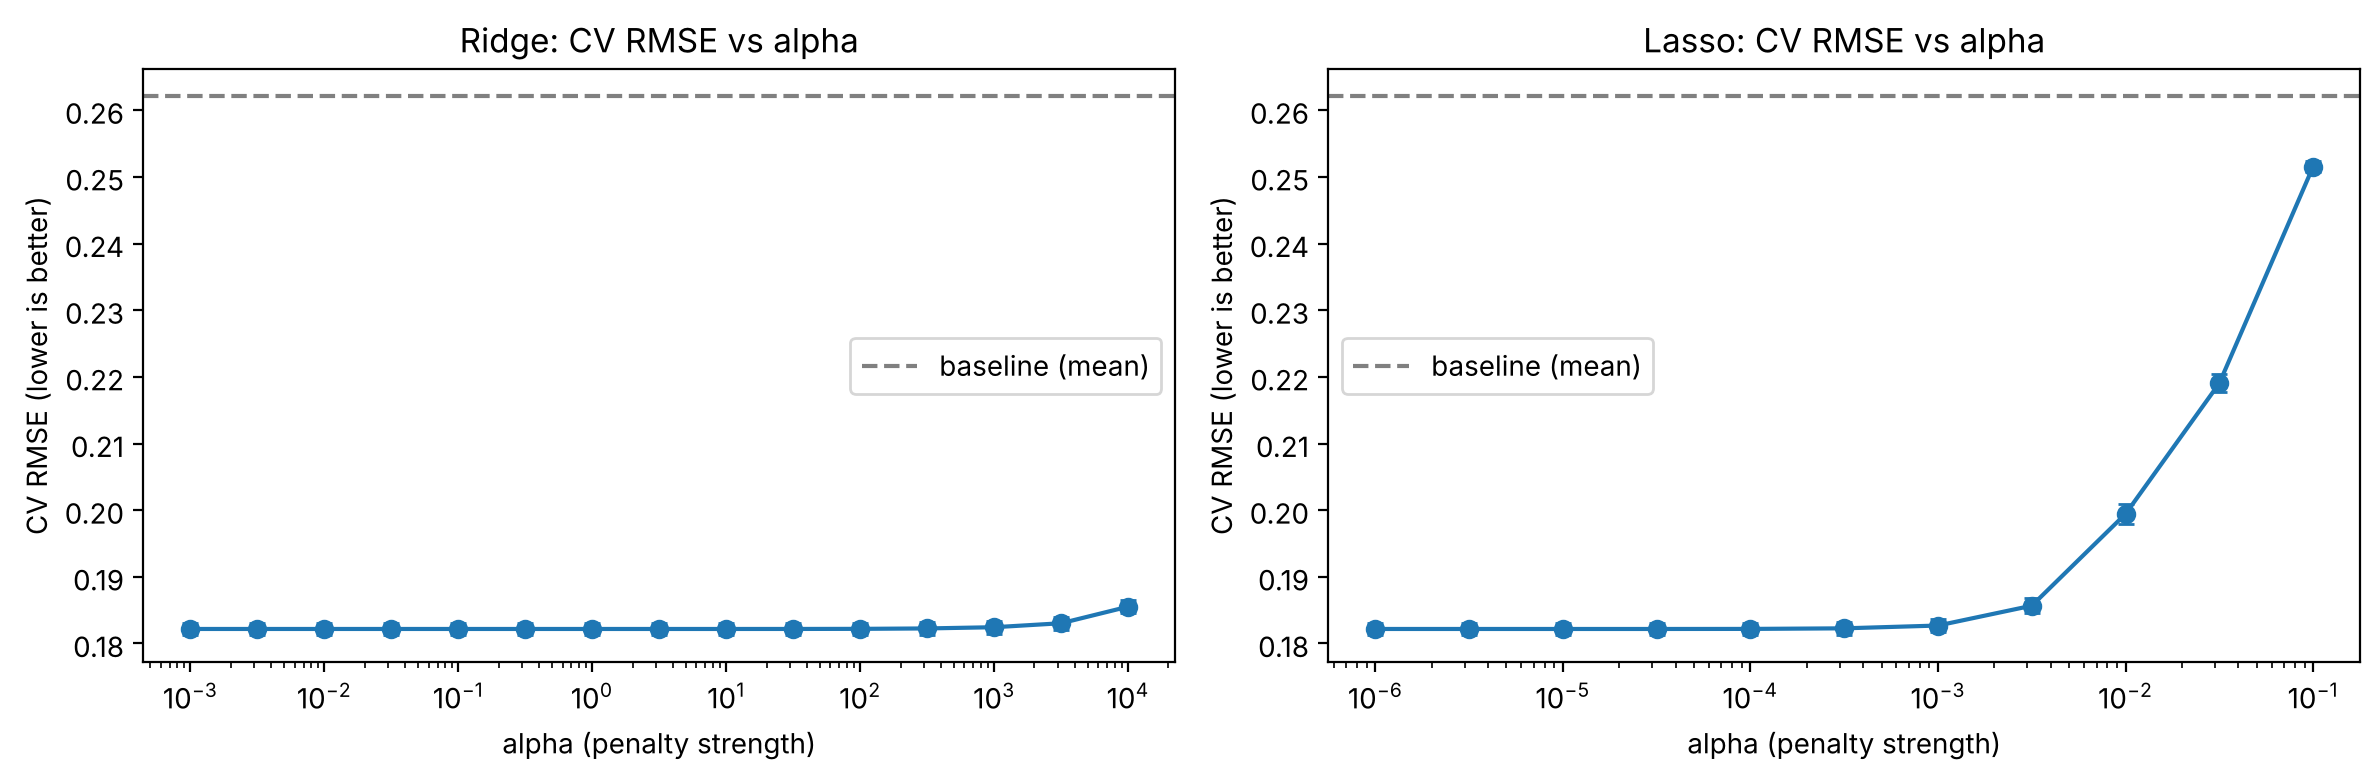

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grid, name in [(axes[0], ridge_grid, "Ridge"), (axes[1], lasso_grid, "Lasso")]:
    alphas = grid.cv_results_["param_model__alpha"].data.astype(float)
    mean_rmse = -grid.cv_results_["mean_test_score"]
    std_rmse = grid.cv_results_["std_test_score"]
    ax.errorbar(alphas, mean_rmse, yerr=std_rmse, marker="o", capsize=3)
    ax.axhline(reg_results[0]["RMSE"], color="gray", ls="--", label="baseline (mean)")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (penalty strength)")
    ax.set_ylabel("CV RMSE (lower is better)")
    ax.set_title(f"{name}: CV RMSE vs alpha")
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
eval_regressor("Ridge (tuned)", ridge_grid.best_estimator_,
               notes=f"alpha={ridge_grid.best_params_['model__alpha']:.3g}")
eval_regressor("Lasso (tuned)", lasso_grid.best_estimator_,
               notes=f"alpha={lasso_grid.best_params_['model__alpha']:.3g}");

Ridge (tuned): RMSE 0.1822 (+/- 0.0009), MAE 0.1464, R2 0.5170


Lasso (tuned): RMSE 0.1822 (+/- 0.0009), MAE 0.1465, R2 0.5170


Ridge and lasso score the same as plain linear regression, and a large alpha only makes things worse.
We have about 63,000 songs and 141 features, so the model isn't overfitting and the penalty doesn't have much to fix.

### 4.3 Polynomial features

Feature engineering added squared terms for energy and acousticness and an energy × acousticness term. Here we go further and add every squared and pairwise product term for the 9 continuous audio features, to see if other curves or interactions matter. We don't do this for the genre and key columns, since it would add thousands of columns.

In [11]:
ridge_poly_grid = GridSearchCV(make_pipe(Ridge(), poly=True), {"model__alpha": np.logspace(-2, 4, 13)},
                               cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_poly_grid.fit(X, y)
print("Best alpha:", ridge_poly_grid.best_params_["model__alpha"])

eval_regressor("Ridge + degree-2 polynomial (tuned)", ridge_poly_grid.best_estimator_,
               notes=f"alpha={ridge_poly_grid.best_params_['model__alpha']:.3g}");

Best alpha: 31.622776601683793


Ridge + degree-2 polynomial (tuned): RMSE 0.1787 (+/- 0.0010), MAE 0.1429, R2 0.5352


This lowers RMSE from 0.182 to 0.179 (R² 0.517 to 0.535). That gain is bigger than the gain from feature engineering, so the hand-picked squared and interaction terms don't capture every curve or interaction. Models that learn these on their own, like trees, may do better.

### 4.4 Lasso path

As alpha goes up, lasso sets more coefficients to 0. Features that stay in the longest are the most useful. We use the 17 features that aren't genre or key columns, so the plot is readable.

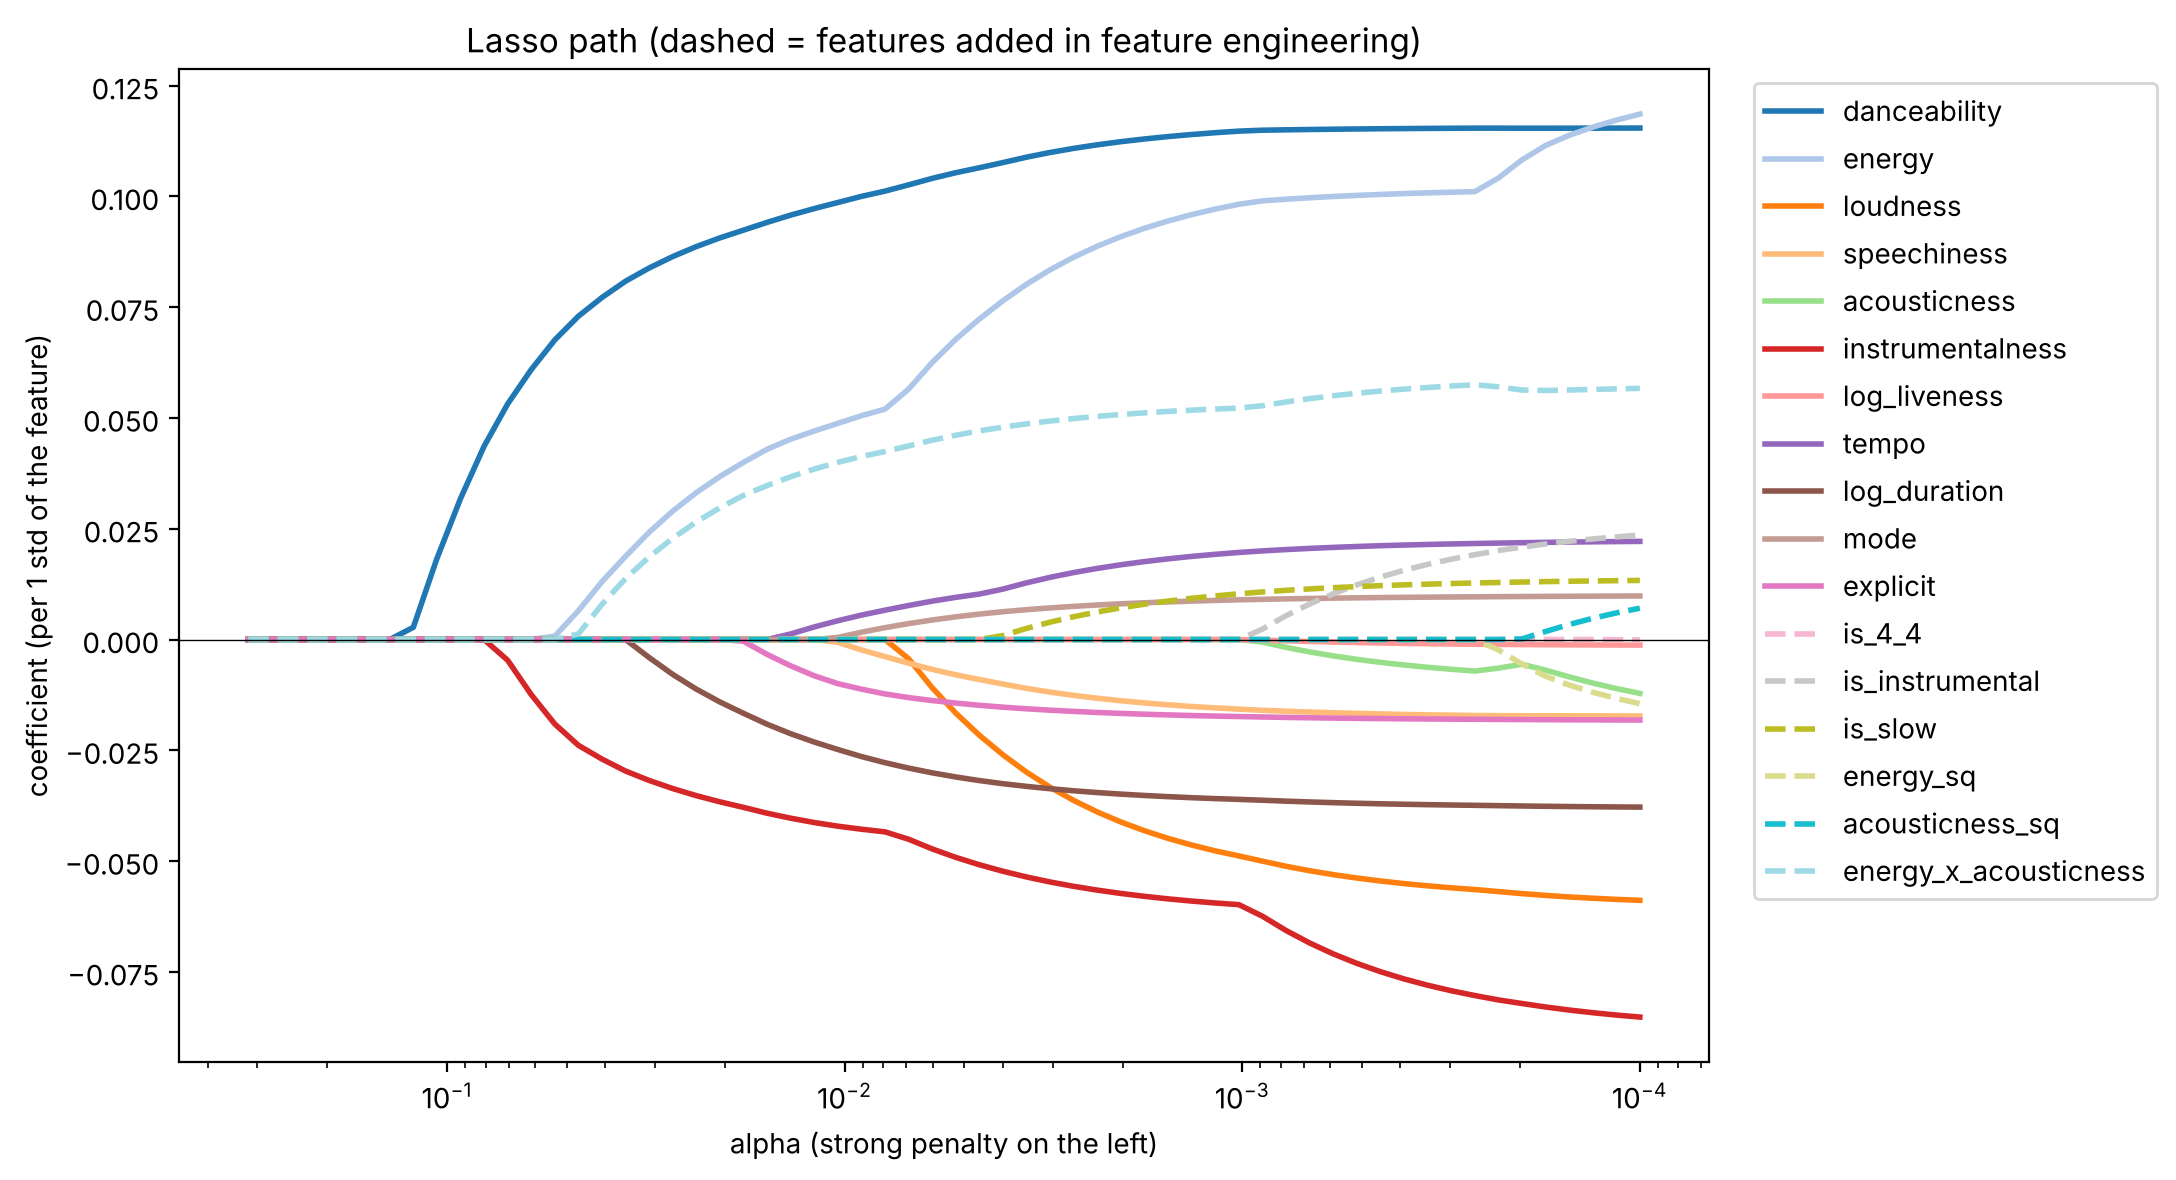

Features in the order lasso keeps them (first = most important):
  danceability           enters at alpha = 0.1215
  instrumentalness       enters at alpha = 0.0704
  energy                 enters at alpha = 0.0536
  energy_x_acousticness  enters at alpha = 0.0467
  log_duration           enters at alpha = 0.0310
  explicit               enters at alpha = 0.0180
  tempo                  enters at alpha = 0.0137
  speechiness            enters at alpha = 0.0104
  mode                   enters at alpha = 0.0104
  loudness               enters at alpha = 0.0069
  is_slow                enters at alpha = 0.0040
  acousticness           enters at alpha = 0.0009
  log_liveness           enters at alpha = 0.0009
  is_instrumental        enters at alpha = 0.0009
  energy_sq              enters at alpha = 0.0002
  acousticness_sq        enters at alpha = 0.0002
  is_4_4                 enters at alpha = 0.0001


In [12]:
X_small_scaled = StandardScaler().fit_transform(X[SMALL_COLS])
alphas_path, coefs_path, _ = lasso_path(X_small_scaled, y - y.mean(), alphas=np.logspace(-4, -0.5, 60))

fig, ax = plt.subplots(figsize=(11, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(SMALL_COLS)))
for i, col in enumerate(SMALL_COLS):
    ax.plot(alphas_path, coefs_path[i], label=col, color=colors[i], lw=2,
            ls="--" if col in ENGINEERED_TERMS or col.startswith("is_") else "-")
ax.set_xscale("log")
ax.invert_xaxis()                       # left = strong penalty, right = weak penalty
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("alpha (strong penalty on the left)")
ax.set_ylabel("coefficient (per 1 std of the feature)")
ax.set_title("Lasso path (dashed = features added in feature engineering)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Order in which features first become non-zero (as the penalty gets weaker)
first_alpha = {col: (alphas_path[np.nonzero(coefs_path[i])[0][0]] if np.any(coefs_path[i]) else 0)
               for i, col in enumerate(SMALL_COLS)}
print("Features in the order lasso keeps them (first = most important):")
for col, a in sorted(first_alpha.items(), key=lambda kv: -kv[1]):
    print(f"  {col:22s} enters at alpha = {a:.4f}")

Danceability is kept first, then instrumentalness, energy, and energy × acousticness. That interaction term is the most useful feature added in feature engineering. The other engineered features come in late with small coefficients, and `is_4_4` comes in last.

Mode also comes in late with a small coefficient, so major vs. minor key barely matters.

### 4.5 Regression results (cross-validation)

In [13]:
pd.DataFrame(reg_results).round(4)

,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,"Linear regression (raw, no genre)",0.2070,0.0016,0.1689,0.3762,before feature engineering
2,Linear regression (raw + genre),0.1842,0.0009,0.1480,0.5060,before feature engineering
3,"Linear regression (engineered, no genre)",0.2035,0.0018,0.1660,0.3971,engineered features
4,Linear regression (engineered + genre),0.1822,0.0009,0.1464,0.5170,engineered features
5,Ridge (tuned),0.1822,0.0009,0.1464,0.5170,alpha=3.16
6,Lasso (tuned),0.1822,0.0009,0.1465,0.5170,alpha=3.16e-05
7,Ridge + degree-2 polynomial (tuned),0.1787,0.0010,0.1429,0.5352,alpha=31.6


## 5. Classification

### 5.1 Logistic regression

We tune `C` (smaller C means a stronger penalty) and `class_weight`. Since only 31% of songs are sad, `class_weight="balanced"` makes mistakes on sad songs count more. We score with ROC-AUC.

In [14]:
logreg_grid = GridSearchCV(make_pipe(LogisticRegression(max_iter=3000)),
                           {"model__C": np.logspace(-3, 2, 6),
                            "model__class_weight": [None, "balanced"]},
                           cv=skf, scoring="roc_auc", n_jobs=-1)
logreg_grid.fit(X, y_sad)
print("Best settings:", logreg_grid.best_params_)
print(f"Best CV ROC-AUC: {logreg_grid.best_score_:.4f}")

Best settings: {'model__C': np.float64(100.0), 'model__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8656


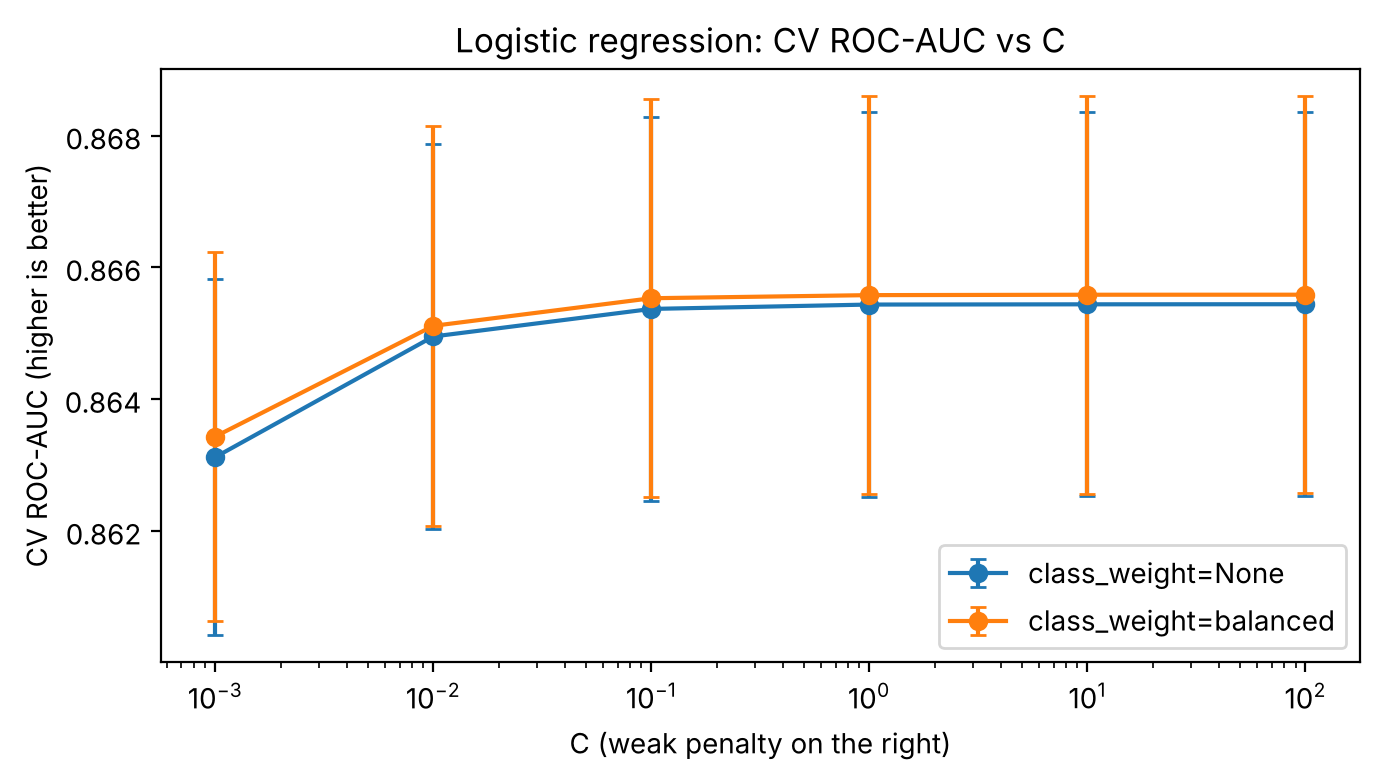

In [15]:
cv = pd.DataFrame(logreg_grid.cv_results_)
cv["class_weight"] = cv["param_model__class_weight"].map(lambda v: "balanced" if v == "balanced" else "None")
fig, ax = plt.subplots(figsize=(7, 4))
for cw, g in cv.groupby("class_weight"):
    ax.errorbar(g["param_model__C"].astype(float), g["mean_test_score"], yerr=g["std_test_score"],
                marker="o", capsize=3, label=f"class_weight={cw}")
ax.set_xscale("log")
ax.set_xlabel("C (weak penalty on the right)")
ax.set_ylabel("CV ROC-AUC (higher is better)")
ax.set_title("Logistic regression: CV ROC-AUC vs C")
ax.legend()
plt.tight_layout()
plt.show()

ROC-AUC levels off from about C = 0.1, so any C from 0.1 to 100 gives almost the same score (grid search picks C = 100 by a very small margin). Class weight barely changes ROC-AUC, since ROC-AUC only depends on how songs are ranked, not on the threshold.

As in regression, we also check logistic regression on the features before feature engineering, with the same settings and folds.

In [16]:
logreg_raw = Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), RAW_NUM),
                                                  ("cat", OneHotEncoder(handle_unknown="ignore"),
                                                   ["track_genre", "key", "time_signature"])])),
                       ("model", LogisticRegression(max_iter=3000, C=logreg_grid.best_params_["model__C"],
                                                    class_weight=logreg_grid.best_params_["model__class_weight"]))])
raw_auc = cross_validate(logreg_raw, X_raw, y_sad, cv=skf, scoring="roc_auc", n_jobs=-1)["test_score"].mean()
print(f"CV ROC-AUC before feature engineering: {raw_auc:.4f}, after: {logreg_grid.best_score_:.4f}")

CV ROC-AUC before feature engineering: 0.8625, after: 0.8656


Feature engineering raises ROC-AUC a little, from 0.8625 to 0.8656.

### 5.2 Choosing the threshold

We pick the threshold that gives the best F1, using out-of-fold predictions on the training set.

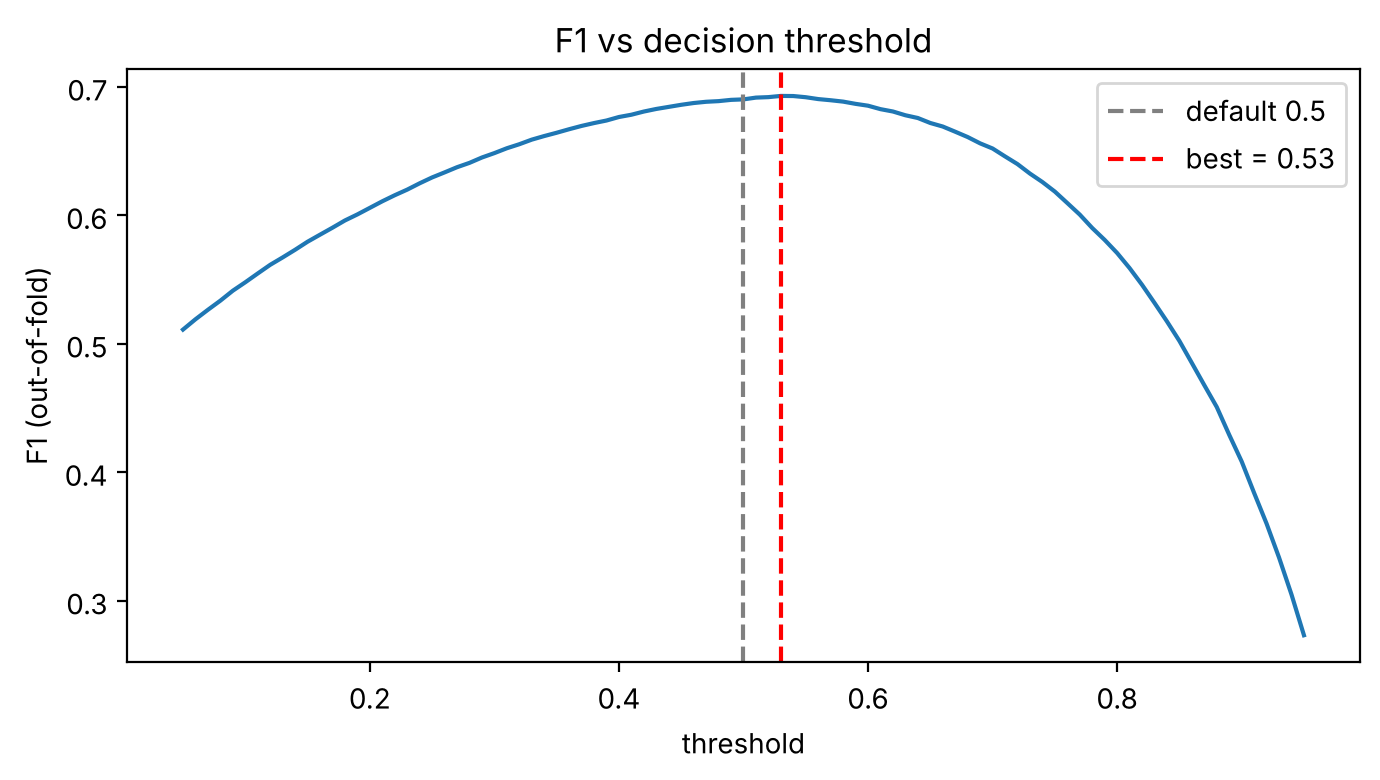

Best threshold: 0.53, F1 = 0.6930 (vs. 0.6903 at 0.5)


In [17]:
best_logreg = logreg_grid.best_estimator_
oof_proba = cross_val_predict(best_logreg, X, y_sad, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_sad, (oof_proba >= t).astype(int)) for t in thresholds]
best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, f1s)
ax.axvline(0.5, color="gray", ls="--", label="default 0.5")
ax.axvline(best_t, color="red", ls="--", label=f"best = {best_t:.2f}")
ax.set_xlabel("threshold")
ax.set_ylabel("F1 (out-of-fold)")
ax.set_title("F1 vs decision threshold")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Best threshold: {best_t:.2f}, F1 = {max(f1s):.4f} (vs. {f1_score(y_sad, (oof_proba >= 0.5).astype(int)):.4f} at 0.5)")

In [18]:
cw_note = f"C={logreg_grid.best_params_['model__C']:.3g}, class_weight={logreg_grid.best_params_['model__class_weight']}"
eval_classifier("Logistic regression (tuned, threshold 0.5)", best_logreg, threshold=0.5, notes=cw_note)
eval_classifier(f"Logistic regression (tuned, threshold {best_t:.2f})", best_logreg, threshold=best_t, notes=cw_note);

Logistic regression (tuned, threshold 0.5): F1 0.6903, ROC-AUC 0.8656, accuracy 0.7829


Logistic regression (tuned, threshold 0.53): F1 0.6930, ROC-AUC 0.8656, accuracy 0.7916


The best threshold is 0.53, close to 0.5, because the balanced class weights already make up for the imbalance. As a check, here is the same search without class weights.

In [19]:
unweighted = make_pipe(LogisticRegression(C=logreg_grid.best_params_["model__C"], max_iter=3000))
oof_unw = cross_val_predict(unweighted, X, y_sad, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
f1s_unw = [f1_score(y_sad, (oof_unw >= t).astype(int)) for t in thresholds]
best_t_unw = round(float(thresholds[int(np.argmax(f1s_unw))]), 2)
print(f"No class weights, threshold 0.50: F1 = {f1_score(y_sad, (oof_unw >= 0.5).astype(int)):.4f}")
print(f"No class weights, best threshold {best_t_unw:.2f}: F1 = {max(f1s_unw):.4f}")

No class weights, threshold 0.50: F1 = 0.6552
No class weights, best threshold 0.33: F1 = 0.6925


Without class weights, F1 at 0.5 drops to 0.655, but moving the threshold down to 0.33 brings it back to 0.693, the same as the balanced model. Both approaches fix the same problem.

The threshold was picked on the same predictions it's scored on, so that F1 is a little optimistic. The test set gives the real number.

### 5.3 Confusion matrix, ROC and precision-recall curves

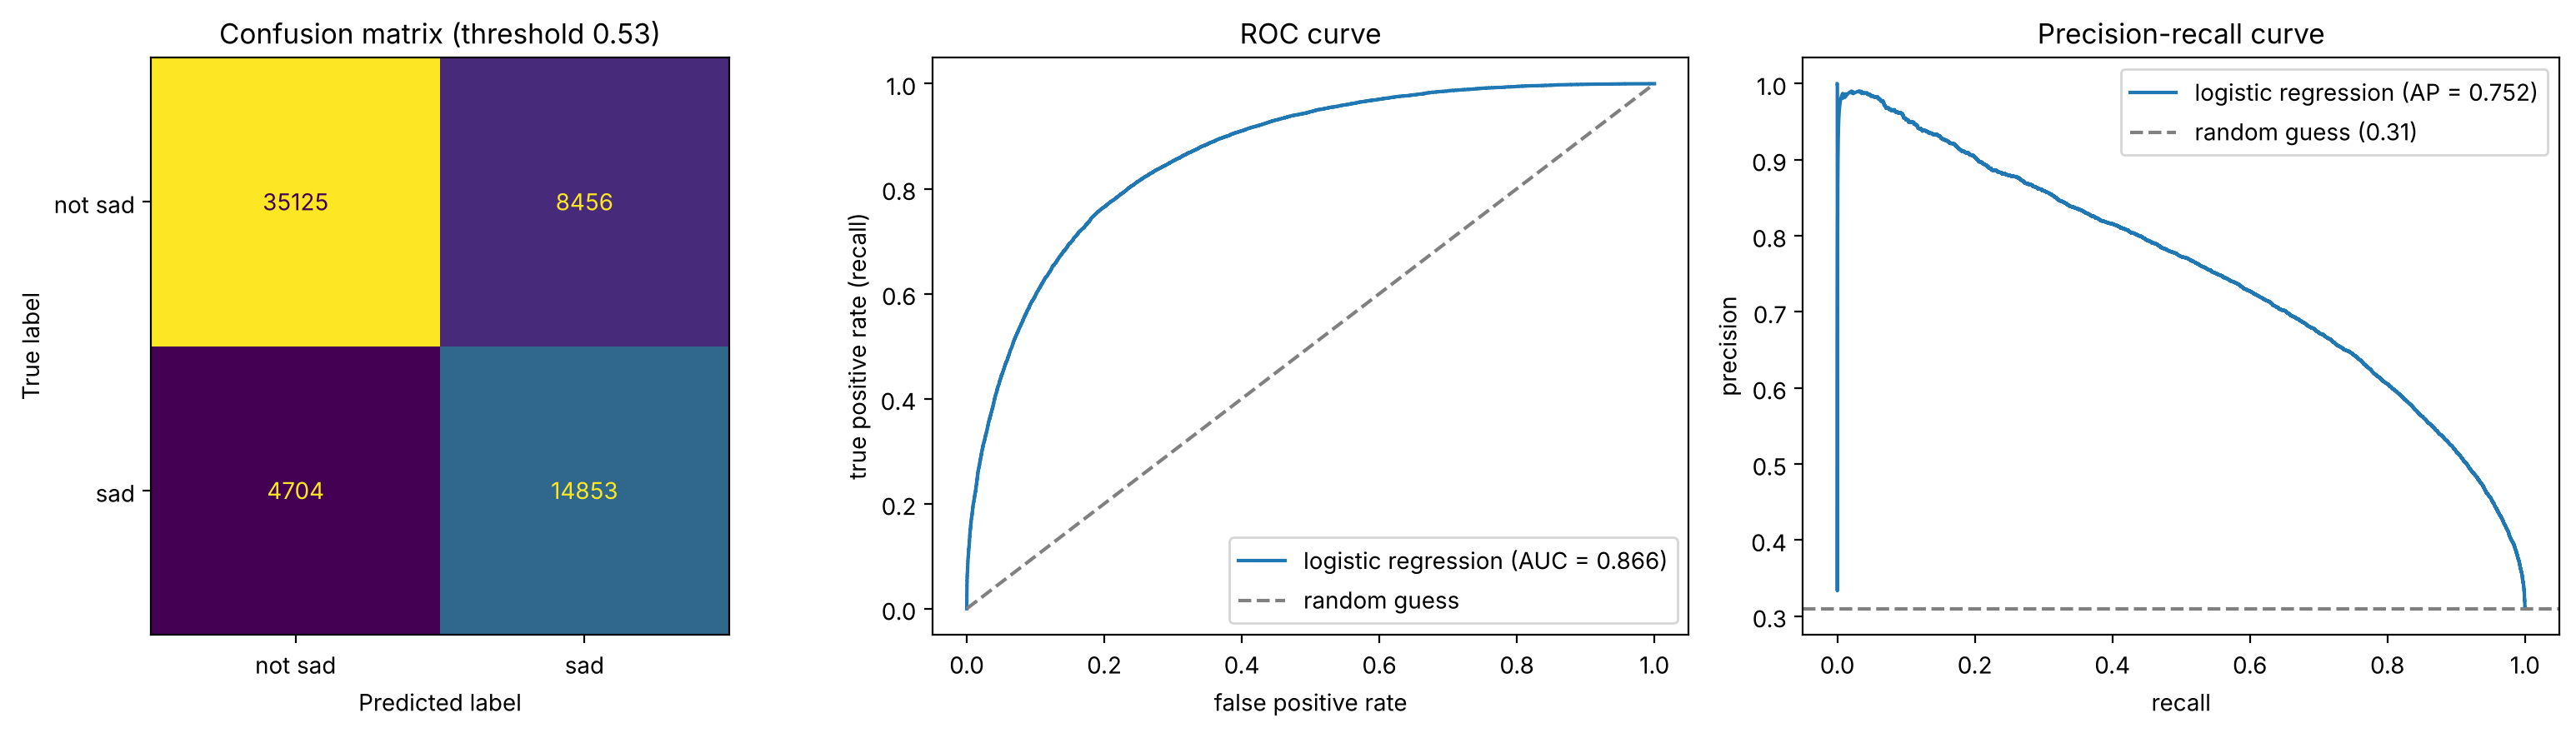

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_sad, (oof_proba >= best_t).astype(int)),
                       display_labels=["not sad", "sad"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {best_t:.2f})")

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
axes[1].plot(fpr, tpr, label=f"logistic regression (AUC = {roc_auc_score(y_sad, oof_proba):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--", label="random guess")
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()

prec, rec, _ = precision_recall_curve(y_sad, oof_proba)
axes[2].plot(rec, prec, label=f"logistic regression (AP = {average_precision_score(y_sad, oof_proba):.3f})")
axes[2].axhline(y_sad.mean(), color="gray", ls="--", label=f"random guess ({y_sad.mean():.2f})")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
axes[2].set_title("Precision-recall curve")
axes[2].legend()

plt.tight_layout()
plt.show()

### 5.4 Classification results (cross-validation)

In [21]:
pd.DataFrame(clf_results).round(4)

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,"Logistic regression (tuned, threshold 0.5)",0.50,0.6903,0.8656,0.7829,"C=100, class_weight=balanced"
2,"Logistic regression (tuned, threshold 0.53)",0.53,0.6930,0.8656,0.7916,"C=100, class_weight=balanced"


## 6. Interpreting the models

### 6.1 Ridge coefficients

The features are scaled, so each coefficient is the change in valence for a one standard deviation increase.

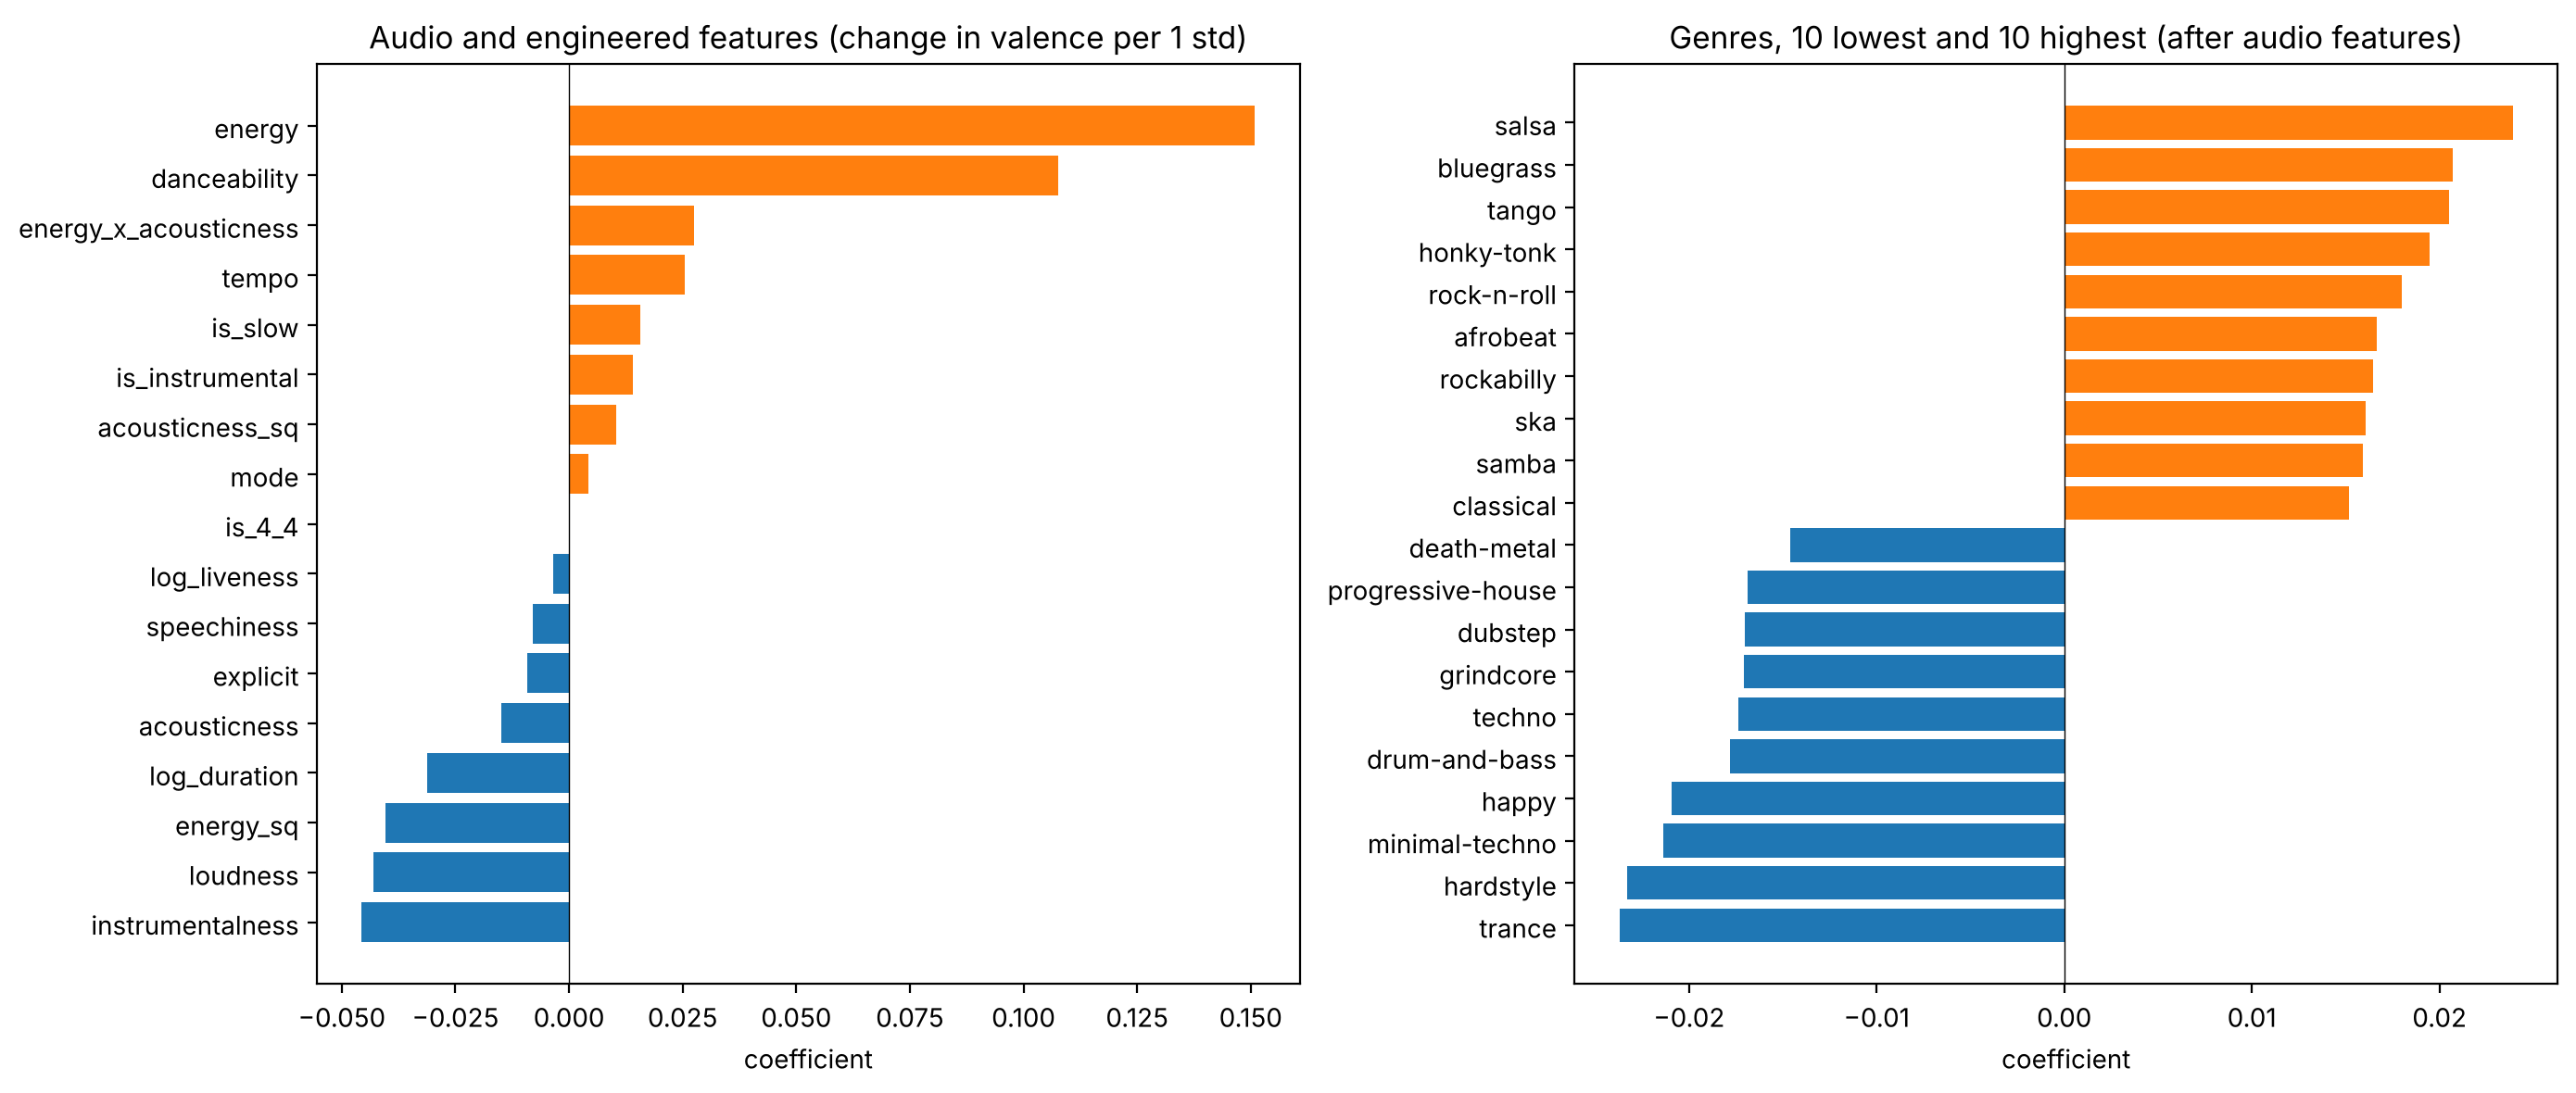

In [22]:
ridge_best = ridge_grid.best_estimator_.fit(X, y)
coefs = pd.Series(ridge_best.named_steps["model"].coef_, index=X.columns)

small_coefs = coefs[SMALL_COLS].sort_values()
genre_coefs = coefs[GENRE_COLS].rename(lambda n: n.replace("genre_", "")).sort_values()
genre_show = pd.concat([genre_coefs.head(10), genre_coefs.tail(10)])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(small_coefs.index, small_coefs.values, color=np.where(small_coefs.values < 0, "tab:blue", "tab:orange"))
axes[0].axvline(0, color="black", lw=0.5)
axes[0].set_title("Audio and engineered features (change in valence per 1 std)")
axes[0].set_xlabel("coefficient")
axes[1].barh(genre_show.index, genre_show.values, color=np.where(genre_show.values < 0, "tab:blue", "tab:orange"))
axes[1].axvline(0, color="black", lw=0.5)
axes[1].set_title("Genres, 10 lowest and 10 highest (after audio features)")
axes[1].set_xlabel("coefficient")
plt.tight_layout()
plt.show()

Energy and danceability have the largest positive coefficients, and `energy_sq` is negative. Together they give the curve the EDA found, where valence rises with energy and then drops for the most energetic songs. Instrumentalness and loudness are the most negative. Mode is close to 0, and `is_4_4` is 0, so the 4/4 flag adds nothing once the other features are in.

The energy × acousticness term is positive. Among very energetic songs, the more acoustic ones are happier, which matches what feature engineering found.

The genre coefficients are adjustments on top of the audio features. Trance, hardstyle, and techno songs are energetic and danceable, so the audio features predict a high valence, but their actual valence is lower, so they get negative coefficients. The same happens to the "happy" genre. Classical goes the other way.

### 6.2 Permutation importance

We shuffle a feature and see how much the RMSE goes up on a validation set (20% of the training set). Some features are spread over several columns, so we shuffle those columns together. All 112 genre columns are shuffled as one group and all 12 key columns as another, and each feature is shuffled together with the engineered columns built from it (for example energy with `energy_sq`).

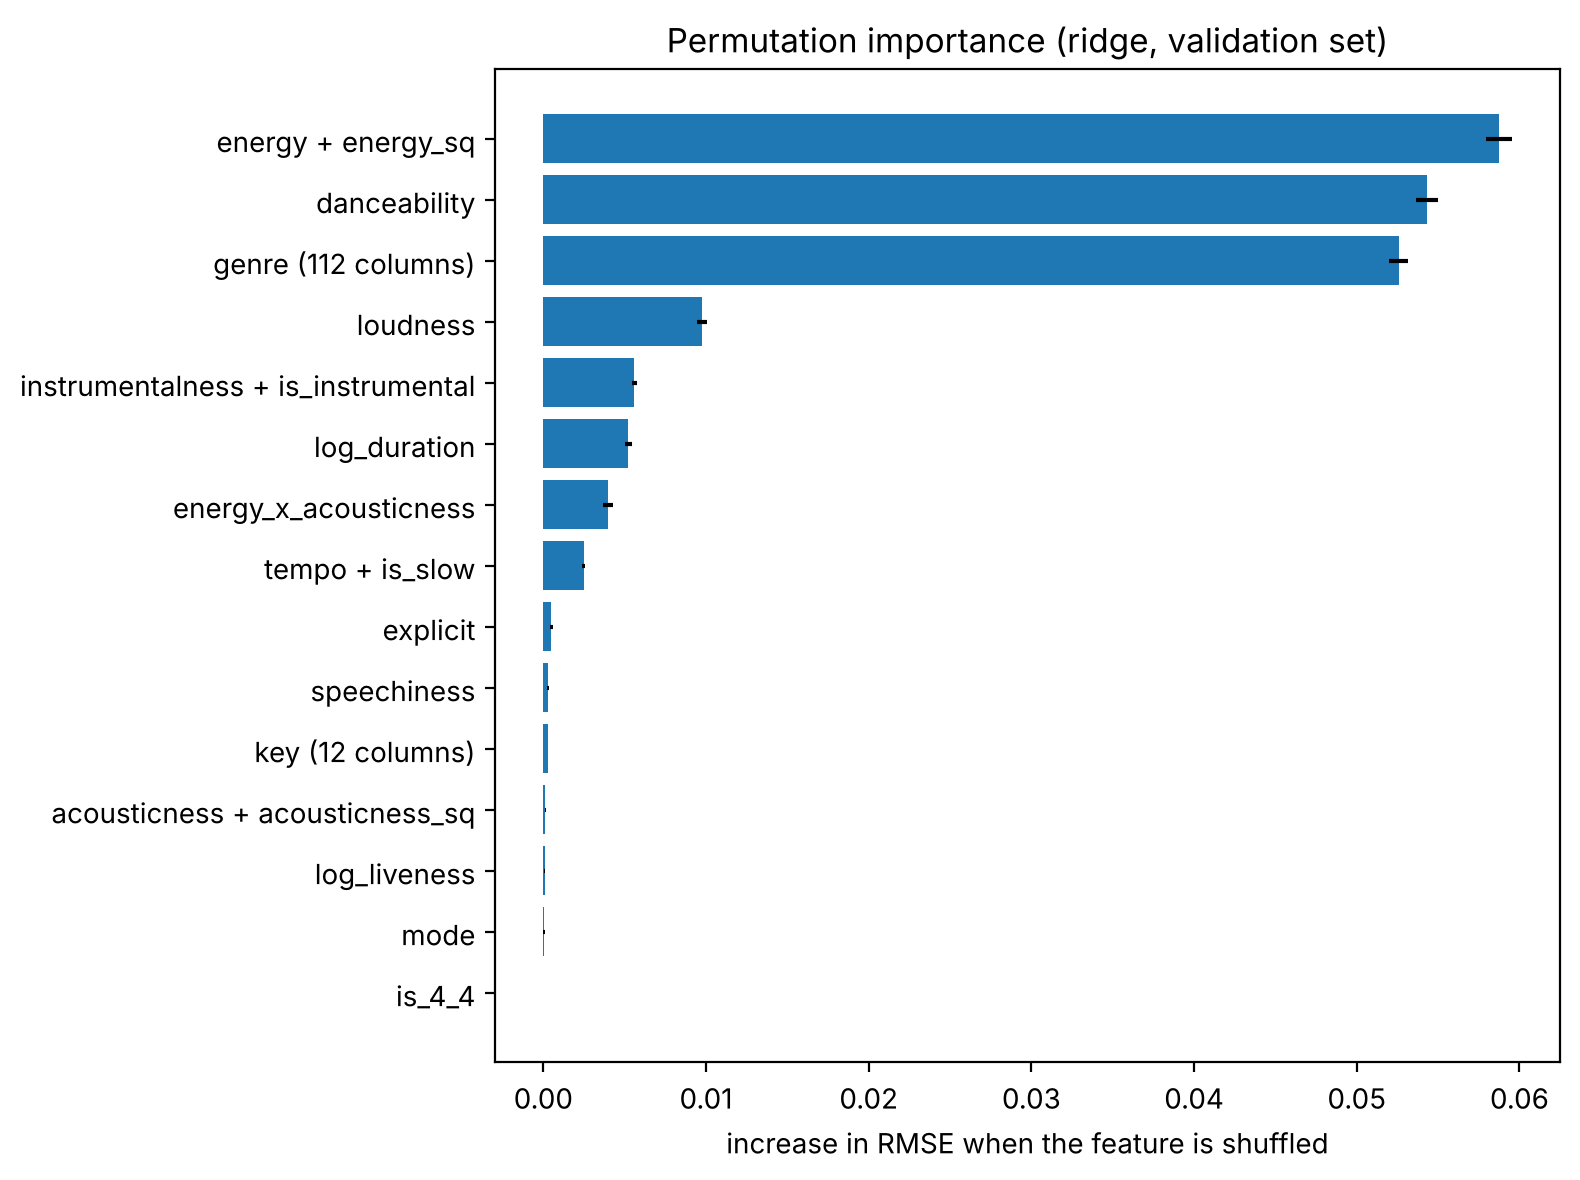

,increase_in_RMSE,std
feature,,
energy + energy_sq,0.0587,0.0008
danceability,0.0543,0.0007
genre (112 columns),0.0526,0.0006
loudness,0.0097,0.0003
instrumentalness + is_instrumental,0.0056,0.0002
log_duration,0.0052,0.0002
energy_x_acousticness,0.0040,0.0003
tempo + is_slow,0.0025,0.0001
explicit,0.0005,0.0001


In [23]:
FEATURE_GROUPS = {
    "genre (112 columns)": GENRE_COLS,
    "key (12 columns)": KEY_COLS,
    "energy + energy_sq": ["energy", "energy_sq"],
    "acousticness + acousticness_sq": ["acousticness", "acousticness_sq"],
    "energy_x_acousticness": ["energy_x_acousticness"],
    "instrumentalness + is_instrumental": ["instrumentalness", "is_instrumental"],
    "tempo + is_slow": ["tempo", "is_slow"],
}
grouped = {c for cols in FEATURE_GROUPS.values() for c in cols}
FEATURE_GROUPS.update({c: [c] for c in X.columns if c not in grouped})

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
perm_model = ridge_grid.best_estimator_.fit(X_tr, y_tr)
base_rmse = np.sqrt(mean_squared_error(y_val, perm_model.predict(X_val)))

rng = np.random.default_rng(RANDOM_STATE)
rows = []
for name, cols in FEATURE_GROUPS.items():
    increases = []
    for _ in range(5):
        X_shuffled = X_val.copy()
        X_shuffled[cols] = X_val[cols].values[rng.permutation(len(X_val))]   # shuffle the group's rows together
        increases.append(np.sqrt(mean_squared_error(y_val, perm_model.predict(X_shuffled))) - base_rmse)
    rows.append({"feature": name, "increase_in_RMSE": np.mean(increases), "std": np.std(increases)})
perm_imp = pd.DataFrame(rows).set_index("feature").sort_values("increase_in_RMSE")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(perm_imp.index, perm_imp["increase_in_RMSE"], xerr=perm_imp["std"])
ax.set_xlabel("increase in RMSE when the feature is shuffled")
ax.set_title("Permutation importance (ridge, validation set)")
plt.tight_layout()
plt.show()
perm_imp.sort_values("increase_in_RMSE", ascending=False).round(4)

Energy (with its squared term), danceability, and genre matter by far the most. Loudness, instrumentalness, duration, and energy × acousticness add a little.

Acousticness on its own adds almost nothing, because its effect is now carried by the energy × acousticness term. Key, mode, liveness, and the 4/4 flag also add almost nothing.

### 6.3 Error analysis

We look at out-of-fold predictions from the polynomial ridge model. Residual = predicted − true.

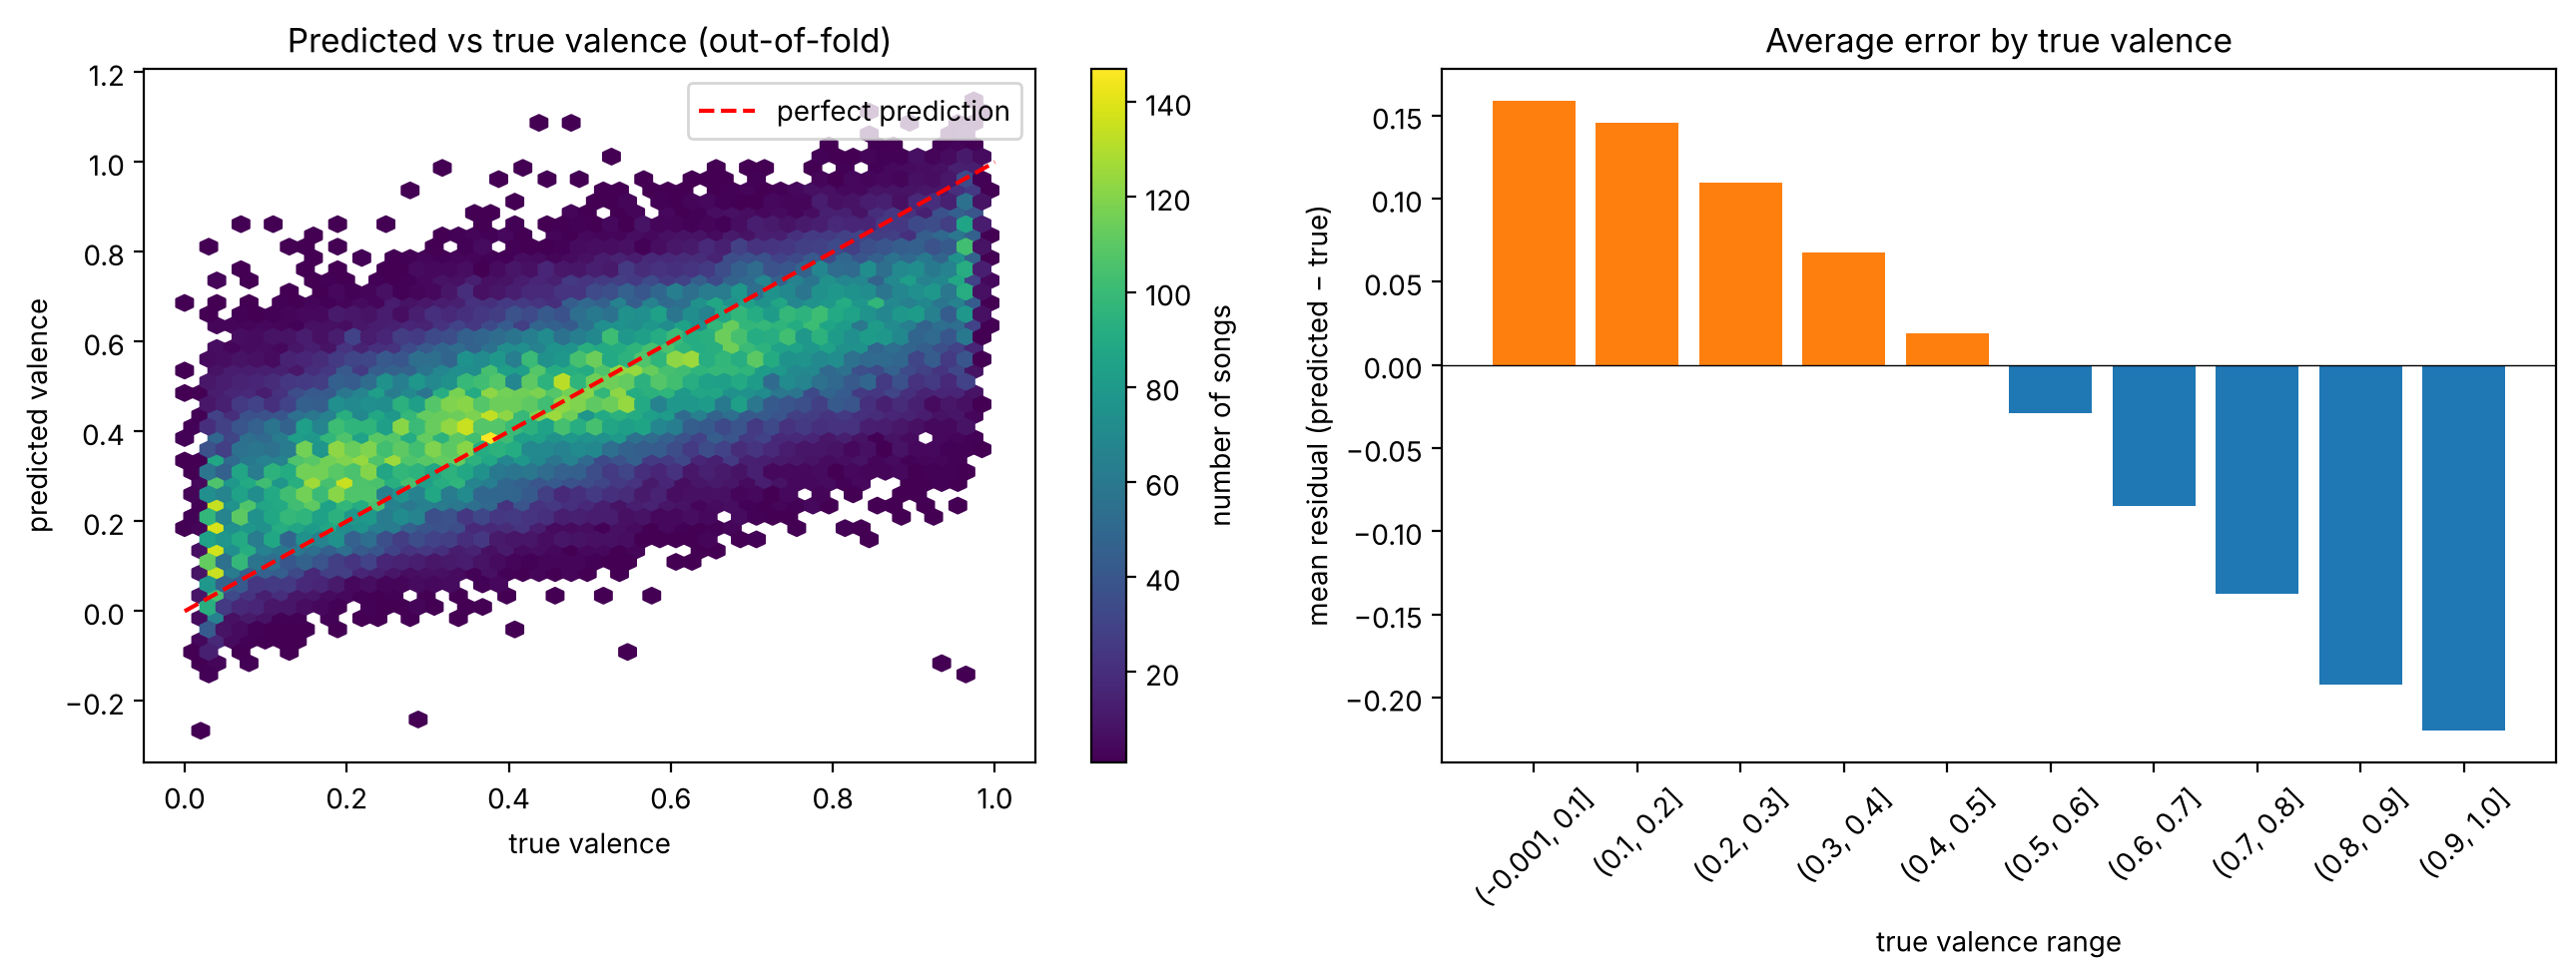

In [24]:
best_reg = ridge_poly_grid.best_estimator_
oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=-1)
resid = oof_pred - y

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hb = axes[0].hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
axes[0].plot([0, 1], [0, 1], color="red", ls="--", label="perfect prediction")
axes[0].set_xlabel("true valence")
axes[0].set_ylabel("predicted valence")
axes[0].set_title("Predicted vs true valence (out-of-fold)")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="number of songs")

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
axes[1].bar([str(b) for b in by_bin.index], by_bin.values,
            color=np.where(by_bin.values > 0, "tab:orange", "tab:blue"))
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_xlabel("true valence range")
axes[1].set_ylabel("mean residual (predicted − true)")
axes[1].set_title("Average error by true valence")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

The model pulls its predictions toward the middle. The saddest songs are predicted too happy and the happiest songs too sad.

The EDA found that low valence covers both calm sad songs and intense ones (like metal). We compare the error for these two groups.

In [25]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4)  ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "all other songs": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()),
           "mean true valence": y[mask].mean(),
           "mean predicted valence": oof_pred[mask].mean(),
           "MAE": resid[mask].abs().mean(),
           "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
error_by_group.round(3)

,songs,mean true valence,mean predicted valence,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.151,0.226,0.108,0.075
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.167,0.331,0.175,0.164
all other songs,43581.0,0.605,0.545,0.138,-0.061


The model does well on calm sad songs (MAE 0.108) but badly on intense low-valence songs (MAE 0.175). It predicts them at 0.33 on average when their true valence is 0.17.
Even with the engineered features, a linear model still learns that more energy means happier, which is wrong for these songs.

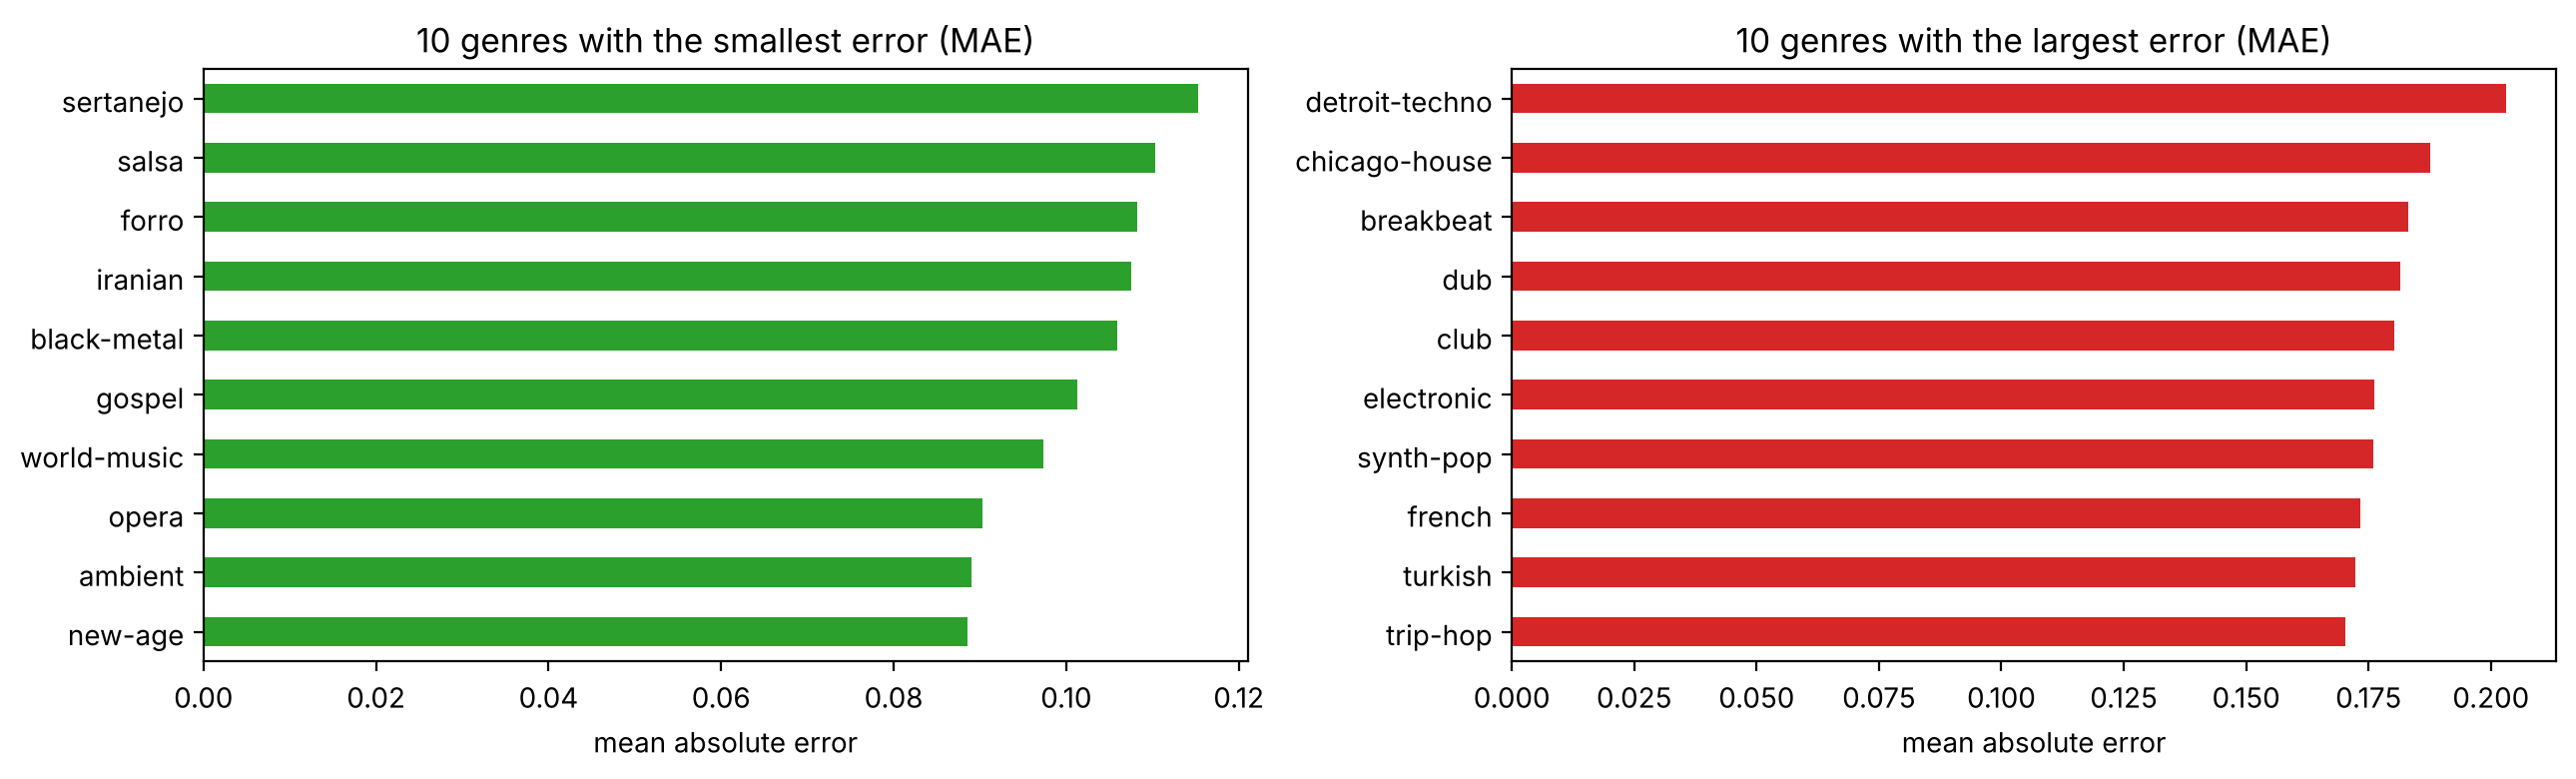

In [26]:
mae_by_genre = resid.abs().groupby(genre).mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mae_by_genre.head(10).plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("10 genres with the smallest error (MAE)")
mae_by_genre.tail(10).plot.barh(ax=axes[1], color="tab:red")
axes[1].set_title("10 genres with the largest error (MAE)")
for ax in axes:
    ax.set_xlabel("mean absolute error")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

The worst genres are mostly electronic dance genres (detroit-techno, chicago-house, breakbeat, club), which is the same problem as above. The best are genres with consistent valence, like new-age, ambient, opera, and black-metal.

## 7. Test set results

We train each final model on the whole training set and score it once on the test set.

In [27]:
test_df = pd.read_csv("test_features.csv")
X_test = test_df.drop(columns=["valence", "sad", "track_genre"])
y_test = test_df["valence"]
y_test_sad = test_df["sad"]
assert list(X_test.columns) == list(X.columns)
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

raw_test = pd.read_csv("test_clean.csv")
X_raw_test = raw_test.drop(columns=["valence"])
X_raw_test["explicit"] = X_raw_test["explicit"].astype(int)
assert (raw_test["valence"].values == y_test.values).all()

final_reg = {
    "Baseline: predict mean": (DummyRegressor(strategy="mean"), X, X_test),
    "Linear regression (raw + genre)": (lin_raw, X_raw, X_raw_test),
    "Linear regression (engineered + genre)": (lin_full, X, X_test),
    "Ridge (tuned)": (ridge_grid.best_estimator_, X, X_test),
    "Ridge + degree-2 polynomial (tuned)": (ridge_poly_grid.best_estimator_, X, X_test),
}
test_reg = []
for name, (model, X_fit, X_score) in final_reg.items():
    pred = model.fit(X_fit, y).predict(X_score)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 141) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,Linear regression (raw + genre),0.1850,0.1488,0.4905
2,Linear regression (engineered + genre),0.1826,0.1468,0.5035
3,Ridge (tuned),0.1826,0.1468,0.5035
4,Ridge + degree-2 polynomial (tuned),0.1791,0.1432,0.5224


In [28]:
final_clf = best_logreg.fit(X, y_sad)
test_proba = final_clf.predict_proba(X_test)[:, 1]
test_clf = []
for t in [0.5, best_t]:
    pred = (test_proba >= t).astype(int)
    test_clf.append({"threshold": t, "model": f"Logistic regression (threshold {t:.2f})",
                     "test F1": f1_score(y_test_sad, pred),
                     "test ROC-AUC": roc_auc_score(y_test_sad, test_proba),
                     "test accuracy": (pred == y_test_sad).mean()})
base_pred = np.zeros_like(y_test_sad)
test_clf.insert(0, {"model": "Baseline: always 'not sad'", "test F1": f1_score(y_test_sad, base_pred),
                    "test ROC-AUC": 0.5, "test accuracy": (base_pred == y_test_sad).mean()})
pd.DataFrame(test_clf).drop(columns="threshold").round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,Logistic regression (threshold 0.50),0.6824,0.8565,0.7764
2,Logistic regression (threshold 0.53),0.6840,0.8565,0.7850


The test scores are close to the cross-validation scores, so the models aren't overfitting. The engineered features also beat the raw features on the test set (R² 0.504 vs. 0.491).

## 8. Summary

- Feature engineering helped the linear models a little. R² went from 0.506 to 0.517 in cross-validation (0.491 to 0.504 on the test set), and ROC-AUC from 0.863 to 0.866. The most useful new feature is energy × acousticness.
- The best regression model is ridge with polynomial features (test R² 0.52, RMSE 0.18, compared to 0.26 for the baseline).
- Logistic regression gets a test F1 of 0.68 and ROC-AUC of 0.86.
- Ridge and lasso don't help over plain linear regression.
- Balanced class weights and a lower threshold give the same F1.
- Minor key doesn't make songs much sadder. Energy matters the most, but in a curved way.
- The biggest errors are still on high-energy songs with low valence, especially in electronic genres.

### Results for the shared sheet

In [29]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left")
clf_table = pd.DataFrame(clf_results)
test_by_t = {r["threshold"]: r for r in test_clf if "threshold" in r}
for col in ["test F1", "test ROC-AUC", "test accuracy"]:
    clf_table[col] = [test_by_t[r["threshold"]][col] if r["model"].startswith("Logistic")
                      else (test_clf[0][col] if r["model"].startswith("Baseline") else np.nan)
                      for _, r in clf_table.iterrows()]
reg_table.to_csv("results_linear_regression.csv", index=False)
clf_table.to_csv("results_linear_classification.csv", index=False)
print("Saved results_linear_regression.csv and results_linear_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_linear_regression.csv and results_linear_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,"Linear regression (raw, no genre)",0.2070,0.0016,0.1689,0.3762,before feature engineering,NaN,NaN,NaN
2,Linear regression (raw + genre),0.1842,0.0009,0.1480,0.5060,before feature engineering,0.1850,0.1488,0.4905
3,"Linear regression (engineered, no genre)",0.2035,0.0018,0.1660,0.3971,engineered features,NaN,NaN,NaN
4,Linear regression (engineered + genre),0.1822,0.0009,0.1464,0.5170,engineered features,0.1826,0.1468,0.5035
5,Ridge (tuned),0.1822,0.0009,0.1464,0.5170,alpha=3.16,0.1826,0.1468,0.5035
6,Lasso (tuned),0.1822,0.0009,0.1465,0.5170,alpha=3.16e-05,NaN,NaN,NaN
7,Ridge + degree-2 polynomial (tuned),0.1787,0.0010,0.1429,0.5352,alpha=31.6,0.1791,0.1432,0.5224


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,0.0000,0.5000,0.6903
1,"Logistic regression (tuned, threshold 0.5)",0.50,0.6903,0.8656,0.7829,"C=100, class_weight=balanced",0.6824,0.8565,0.7764
2,"Logistic regression (tuned, threshold 0.53)",0.53,0.6930,0.8656,0.7916,"C=100, class_weight=balanced",0.6840,0.8565,0.7850
